UNITY CATALOG 

In [0]:
%sql
CREATE OR REPLACE TABLE cafe_orders_demo (
    order_id INT,
    customer_name STRING,
    city STRING,
    amount INT,
    order_status STRING
)
USING DELTA;
 

In [0]:
%sql
INSERT INTO cafe_orders_demo VALUES
(101, 'Ayaan', 'Hyderabad', 450, 'Completed'),
(102, 'Tara', 'Mumbai', 700, 'Pending'),
(103, 'Ishaan', 'Pune', 300, 'Completed'),
(104, 'Sara', 'Hyderabad', 900, 'Completed'),
(105, 'Kabir', 'Delhi', 250, 'Cancelled'),
(106, 'Zoya', 'Mumbai', 600, 'Pending'),
(107, 'Rehan', 'Pune', 800, 'Completed'),
(108, 'Mira', 'Delhi', 550, 'Completed');

num_affected_rows,num_inserted_rows
8,8


In [0]:
%sql
DESCRIBE EXTENDED cafe_orders_demo;
 

col_name,data_type,comment
order_id,int,null
customer_name,string,null
city,string,null
amount,int,null
order_status,string,null
,,
# Delta Statistics Columns,,
Column Names,"city, order_id, customer_name, amount, order_status",
Column Selection Method,first-32,
,,


In [0]:
%sql
show catalogs

catalog
dbt
samples
system


In [0]:
%sql
use catalog dbt;

In [0]:
%sql
SHOW SCHEMAS;

databaseName
default
information_schema


In [0]:
%sql
use schema default;

In [0]:
%sql
show tables;

database,tableName,isTemporary
default,cafe_orders_demo,false
default,cinema_bookings_clean,false
default,cinema_performance_report,false
default,courier_parcels_copy,false
default,courier_parcels_delta,false
default,courier_parcels_pyspark,false
default,fitness_memberships_demo,false
default,office_inventory_demo,false
default,retail_products_ctas,false
default,retail_products_pyspark,false


In [0]:
%sql
select current_catalog(),current_schema();

current_catalog(),current_schema()
dbt,default


In [0]:
%sql
CREATE OR REPLACE TABLE dbt.default.bike_rides_raw (
    ride_id INT,
    station STRING,
    duration_min INT,
    fare DOUBLE,
    status STRING
)
USING DELTA;
 

In [0]:
%sql
INSERT INTO dbt.default.bike_rides_raw VALUES
(1, 'Central', 20, 100.0, 'Completed'),
(2, 'Airport', 35, 180.0, 'Completed'),
(3, 'Metro', 15, 75.0, 'Cancelled'),
(4, 'Central', 40, 200.0, 'Completed'),
(5, 'University', 25, 125.0, 'Completed');
 

num_affected_rows,num_inserted_rows
5,5


In [0]:
%sql
SELECT * FROM dbt.default.bike_rides_raw;

ride_id,station,duration_min,fare,status
1,Central,20,100.0,Completed
2,Airport,35,180.0,Completed
3,Metro,15,75.0,Cancelled
4,Central,40,200.0,Completed
5,University,25,125.0,Completed


In [0]:
%sql
CREATE OR REFRESH STREAMING TABLE bike_bronze_sql
AS
SELECT *
FROM STREAM(dbt.default.bike_rides_raw);

message
The operation was successfully executed.


In [0]:
%sql
CREATE OR REFRESH STREAMING TABLE bike_bronze_sql
AS
SELECT *
FROM STREAM(dbt.default.bike_rides_raw);

message
The operation was successfully executed.


In [0]:
%sql
CREATE OR REFRESH STREAMING TABLE bike_silver_sql
AS
SELECT
    ride_id,
    station,
    duration_min,
    fare
FROM STREAM(bike_bronze_sql)
WHERE status = 'Completed'
  AND duration_min > 0
  AND fare > 0;

message
The operation was successfully executed.


In [0]:
  %sql
CREATE OR REFRESH MATERIALIZED VIEW bike_gold_sql
AS
SELECT
    station,
    COUNT(*) AS total_rides,
    ROUND(SUM(fare), 2) AS total_revenue
FROM bike_silver_sql GROUP BY station;

result
The operation was successfully executed.


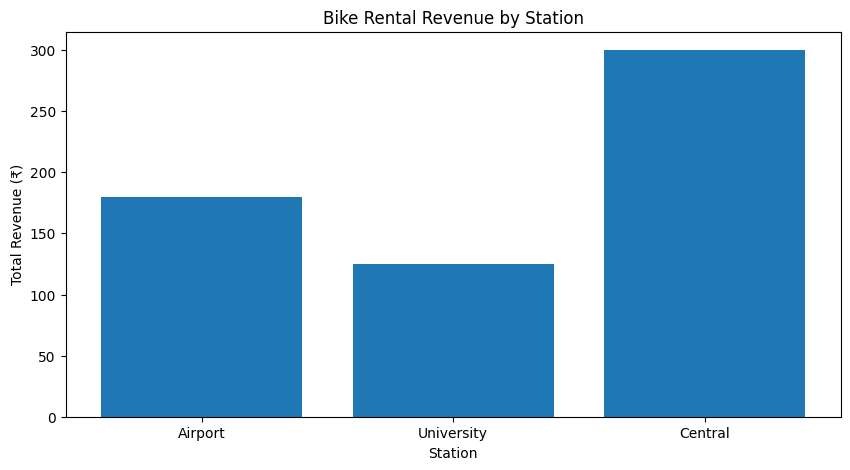

In [0]:
import matplotlib.pyplot as plt
df = spark.sql("""
    SELECT station, total_rides, total_revenue
    FROM dbt.default.bike_gold_sql
""")
pdf = df.toPandas()
plt.figure(figsize=(10, 5))
plt.bar(pdf["station"], pdf["total_revenue"])
plt.xlabel("Station")
plt.ylabel("Total Revenue (₹)")
plt.title("Bike Rental Revenue by Station")
plt.show()

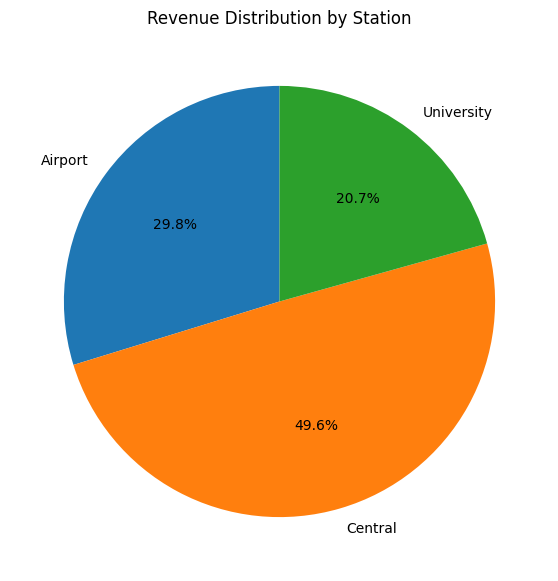

In [0]:
plt.figure(figsize=(7, 7))

plt.pie(
    pdf["total_revenue"],
    labels=pdf["station"],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Revenue Distribution by Station")
plt.show()

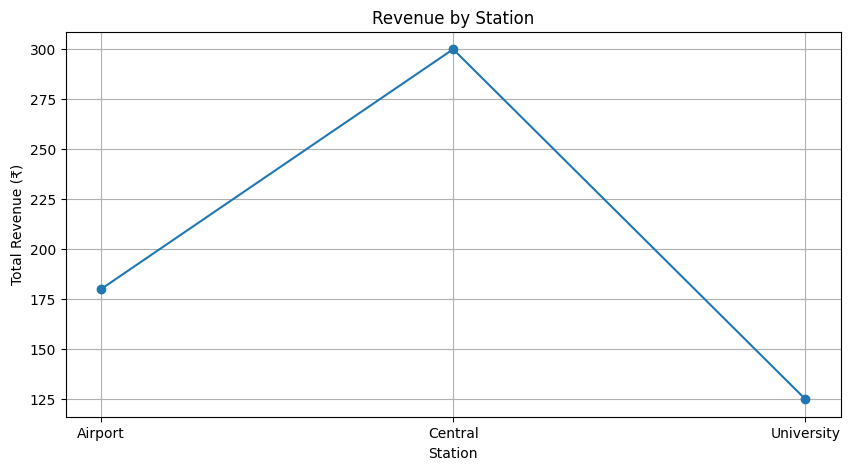

In [0]:
pdf = pdf.sort_values("station")

plt.figure(figsize=(10, 5))

plt.plot(
    pdf["station"],
    pdf["total_revenue"],
    marker="o"
)

plt.xlabel("Station")
plt.ylabel("Total Revenue (₹)")
plt.title("Revenue by Station")
plt.grid(True)
plt.show()  

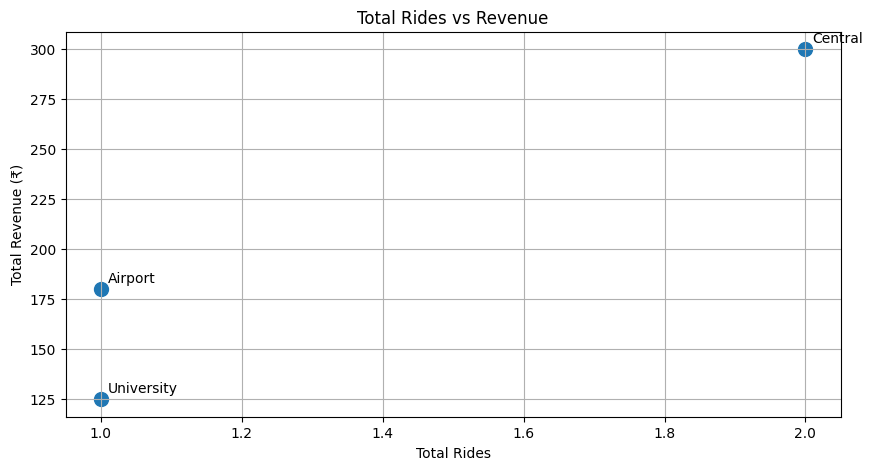

In [0]:
plt.figure(figsize=(10, 5))

plt.scatter(
    pdf["total_rides"],
    pdf["total_revenue"],
    s=100
)

for _, row in pdf.iterrows():
    plt.annotate(
        row["station"],
        (row["total_rides"], row["total_revenue"]),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.xlabel("Total Rides")
plt.ylabel("Total Revenue (₹)")
plt.title("Total Rides vs Revenue")
plt.grid(True)
plt.show()